# Understanding a Brain Tumor Prediction, Step by Step

My goal is to understand **one prediction**, before interpreting any explanation map. I follow three questions:

1. **Where is the annotated tumor?** Look at the MRI and reference mask.
2. **What did the model get right or wrong?** Separate detected, missed, and extra regions.
3. **What changes its score?** Hide one input block and measure the change.

Occlusion is the main explanation. Gradients appear later as an optional, more technical extension. Every main figure is followed by a short reading of its actual numbers. The model is not retrained.

**Dataset:** [BraTS-Africa](https://www.cancerimagingarchive.net/collection/brats-africa/), [Adewole et al.](https://doi.org/10.1148/ryai.240528).

**Source:** personal extension of the [MAI Lab / SPARK Academy tutorial](https://github.com/SPARK-Academy-2025/lightweight-brats-tutorial), discovered at Indaba. The network comes from [my PyTorch training notebook](02_unet3d_pytorch_brain_segmentation.ipynb).

**Method references:** [occlusion, Zeiler and Fergus](https://arxiv.org/abs/1311.2901); [SmoothGrad, Smilkov et al.](https://arxiv.org/abs/1706.03825). These explanations describe model behavior, including errors; they do not demonstrate clinical validity.


## 1. Choose the patient and question

Use the training environment (`torch`, `numpy`, `matplotlib`). Paths work from the repository root or `notebooks`.

The default question is: **which inputs influence the model's edema probability inside the annotated edema region?** This uses `TARGET_CLASS = 2` and `ROI_MODE = "reference"`. It differs from explaining the entire predicted region, which can contain many false positives.

To investigate a specific error later, choose `"false_positive"` or `"false_negative"`. The notebook never silently replaces an empty region. A 64? crop makes CPU execution manageable. Its prediction can differ from whole-volume inference because the surrounding context changes.


In [23]:
from pathlib import Path
import itertools
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from IPython.display import display, Markdown
import torch
import torch.nn as nn
import torch.nn.functional as F

BASE = Path.cwd()
if not (BASE / "saved_model").is_dir() and (BASE / "notebooks" / "saved_model").is_dir():
    BASE /= "notebooks"
CHECKPOINT = BASE / "saved_model" / "3d_unet_pytorch.pt"
DATA_ROOT = BASE / "glioma_split_data"
OUTPUT_DIR = BASE / "xai_results_guided"
CASE_NAME = None
TARGET_CLASS = 2
ROI_MODE = "reference"  # "reference", "predicted", "false_positive", or "false_negative"
RUN_GRADIENT_APPENDIX = True  # False skips the optional gradient explanations.
CROP_SIZE = 64
SMOOTH_SAMPLES = 12
NOISE_STD = 0.05  # Absolute standard deviation in normalized intensity units.
OCCLUSION_SIZE = 16  # Non-overlapping blocks; reduce for finer, slower maps.
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODALITIES = ["t1n", "t1c", "t2f", "t2w"]
CLASS_NAMES = ["background", "necrotic core", "edema", "enhancing tumor"]
assert TARGET_CLASS in (1, 2, 3) and ROI_MODE in ("predicted", "reference", "false_positive", "false_negative")
assert CROP_SIZE >= 16 and CROP_SIZE % 16 == 0
assert 1 <= OCCLUSION_SIZE <= CROP_SIZE and SMOOTH_SAMPLES >= 2 and NOISE_STD > 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max((__import__("os").cpu_count() or 2) // 2, 1))
print("Device:", DEVICE, "| Class:", CLASS_NAMES[TARGET_CLASS], "| ROI:", ROI_MODE)

figures = {}
def explain(text):
    display(Markdown(text))


Device: cpu | Class: edema | ROI: reference


## 2. Restore the trained network

These are the same layers as in training. Strict loading checks compatibility. Evaluation mode disables dropout, and the weights remain frozen.


In [24]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Dropout3d(dropout),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


In [25]:
class UNet3D(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, 16, 0.1)
        self.enc2 = ConvBlock(16, 32, 0.1)
        self.enc3 = ConvBlock(32, 64, 0.2)
        self.enc4 = ConvBlock(64, 128, 0.2)
        self.bottleneck = ConvBlock(128, 256, 0.3)

        self.pool = nn.MaxPool3d(2)

        self.up4 = nn.ConvTranspose3d(256, 128, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(256, 128, 0.2)
        self.up3 = nn.ConvTranspose3d(128, 64, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(128, 64, 0.2)
        self.up2 = nn.ConvTranspose3d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(64, 32, 0.1)
        self.up1 = nn.ConvTranspose3d(32, 16, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(32, 16, 0.1)

        self.out = nn.Conv3d(16, num_classes, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        c2 = self.enc2(self.pool(c1))
        c3 = self.enc3(self.pool(c2))
        c4 = self.enc4(self.pool(c3))
        c5 = self.bottleneck(self.pool(c4))

        u4 = self.dec4(torch.cat([self.up4(c5), c4], dim=1))
        u3 = self.dec3(torch.cat([self.up3(u4), c3], dim=1))
        u2 = self.dec2(torch.cat([self.up2(u3), c2], dim=1))
        u1 = self.dec1(torch.cat([self.up1(u2), c1], dim=1))

        return self.out(u1)


In [26]:
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {CHECKPOINT}")
model = UNet3D(4, 4).to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True), strict=True)
model.eval().requires_grad_(False)
print(f"Loaded {sum(p.numel() for p in model.parameters()):,} parameters")


Loaded 5,646,260 parameters


## 3. Locate the annotation before looking at XAI

The crop is centered using the reference target class, or any reference tumor if that class is absent. This deliberately selects a useful teaching example; it is not an unbiased test-set evaluation.

I select the displayed slice with the largest annotated target area, falling back to the largest annotated tumor area, then the crop center. I keep this same slice for the main figures. Image orientation follows the preprocessed array: these are not scanner-coordinate or clinical left/right displays.


In [27]:
names = sorted((DATA_ROOT / "test" / "images").glob("*.npy"))
if not names:
    raise FileNotFoundError(f"No test images in {DATA_ROOT}")
image_path = names[0] if CASE_NAME is None else DATA_ROOT / "test" / "images" / CASE_NAME
mask_path = DATA_ROOT / "test" / "masks" / image_path.name.replace("image_", "mask_")
image = np.load(image_path, allow_pickle=False).astype(np.float32)
mask = np.load(mask_path, allow_pickle=False)
if image.ndim != 4 or image.shape[-1] != 4 or image.shape != mask.shape:
    raise ValueError("Expected matching (X,Y,Z,4) image and one-hot mask arrays")
if not np.isfinite(image).all() or not np.isfinite(mask).all():
    raise ValueError("Non-finite input or mask")
if not np.all((mask == 0) | (mask == 1)) or not np.all(mask.sum(axis=-1) == 1):
    raise ValueError("Mask must be one-hot encoded")
labels = mask.argmax(axis=-1)
if min(labels.shape) < CROP_SIZE:
    raise ValueError("Crop exceeds the image dimensions")
coords = np.argwhere(labels == TARGET_CLASS)
selection = "reference target region"
if not len(coords):
    coords = np.argwhere(labels > 0)
    selection = "any reference tumor"
center = coords.mean(axis=0).astype(int) if len(coords) else np.array(labels.shape) // 2
if not len(coords):
    selection = "volume center"
start = np.clip(center - CROP_SIZE // 2, 0, np.array(labels.shape) - CROP_SIZE)
crop = tuple(slice(int(s), int(s + CROP_SIZE)) for s in start)
image_crop, reference = image[crop], labels[crop]
x = torch.from_numpy(np.ascontiguousarray(image_crop.transpose(3, 0, 1, 2))).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    original_logits = model(x)
    prediction = original_logits.argmax(dim=1)[0].cpu().numpy()
probability = original_logits.softmax(dim=1)[0, TARGET_CLASS].cpu().numpy()
truth = reference == TARGET_CLASS
pred = prediction == TARGET_CLASS
correct = truth & pred
missed = truth & ~pred
extra = pred & ~truth
metrics = []
for c, name in enumerate(CLASS_NAMES):
    t, q = reference == c, prediction == c
    denominator = int(t.sum() + q.sum())
    dice = float(2 * np.logical_and(t, q).sum() / denominator) if denominator else None
    metrics.append({"class": c, "name": name, "reference_voxels": int(t.sum()),
                    "predicted_voxels": int(q.sum()), "dice": dice})
area = truth.sum(axis=(0, 1))
if not area.any():
    area = (reference > 0).sum(axis=(0, 1))
z = int(area.argmax()) if area.any() else CROP_SIZE // 2
print("Case:", image_path.name, "| crop start:", start.tolist(), "| selection:", selection)
print("Displayed slice:", int(start[2]) + z, "in the original preprocessed array")


Case: image_11.npy | crop start: [28, 12, 0] | selection: reference target region
Displayed slice: 31 in the original preprocessed array


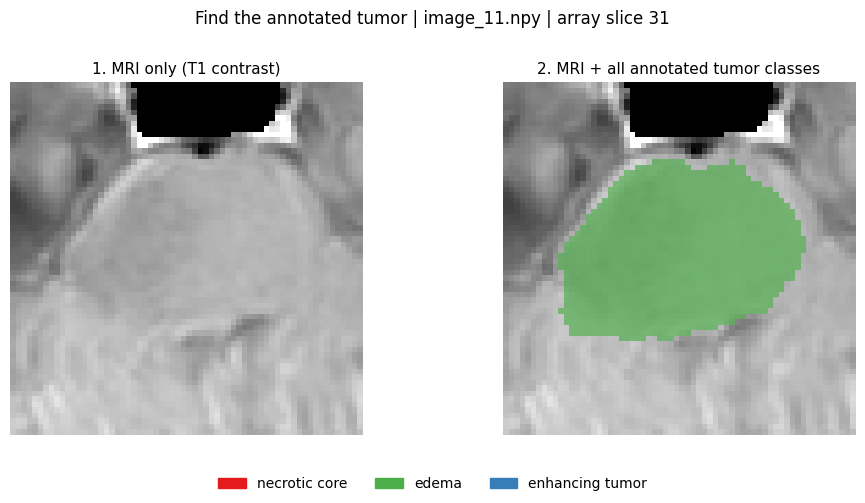

**Read this first:** the colored regions are the reference annotations, not model explanations. The selected class is **edema**. It contains **29,418 annotated voxels in the entire crop**.

In [28]:
# Common display rules: same slice, same image contrast, explicit legends.
def view(array):
    return array[:, :, z].T

background = image_crop[..., 1]
nonzero = background[background > 0]
mri_high = max(float(np.percentile(nonzero, 99)) if nonzero.size else 1.0, 1e-6)
TARGET_COLOR = "#38bdf8"
COLORS = ["#000000", "#e41a1c", "#4daf4a", "#377eb8"]
ERROR_COLORS = ["#00000000", "#22c55e", "#d946ef", "#f59e0b"]

def mri_axis(ax, array=background, title=""):
    ax.imshow(view(array), cmap="gray", vmin=0, vmax=mri_high, origin="lower", interpolation="nearest")
    ax.set_title(title, fontsize=11)
    ax.axis("off")

def overlay(ax, region, color, alpha=0.5):
    shown = np.ma.masked_where(~view(region), np.ones_like(view(region), dtype=float))
    ax.imshow(shown, cmap=ListedColormap([color]), vmin=0, vmax=1,
              alpha=alpha, origin="lower", interpolation="nearest")

def outline(ax, region, color="white", linestyle="solid"):
    sliced = view(region)
    if sliced.any() and not sliced.all():
        ax.contour(sliced.astype(float), levels=[0.5], colors=[color],
                   linewidths=1.2, linestyles=linestyle)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
mri_axis(axes[0], title="1. MRI only (T1 contrast)")
mri_axis(axes[1], title="2. MRI + all annotated tumor classes")
shown = np.ma.masked_where(view(reference) == 0, view(reference))
axes[1].imshow(shown, cmap=ListedColormap(COLORS), vmin=0, vmax=3,
               alpha=0.65, origin="lower", interpolation="nearest")
fig.legend(handles=[Patch(color=COLORS[c], label=CLASS_NAMES[c]) for c in (1, 2, 3)],
           loc="lower center", ncol=3, frameon=False)
fig.suptitle(f"Find the annotated tumor | {image_path.name} | array slice {int(start[2]) + z}")
fig.tight_layout(rect=(0, 0.10, 1, 0.94))
figures["01_annotation"] = fig
plt.show()
explain("**Read this first:** the colored regions are the reference annotations, not model explanations. "
        f"The selected class is **{CLASS_NAMES[TARGET_CLASS]}**. It contains **{int(truth.sum()):,} annotated voxels in the entire crop**.")


## 4. Separate correct detections from errors

This figure concerns **only the selected class**. Green means the model and reference agree on that class. Magenta means the model missed it. Orange means the model predicted it outside its annotation. Uncolored pixels are outside these three groups, not necessarily healthy tissue.

The figure is one slice. Counts, Dice, precision, and recall below use the **entire crop**. Precision asks how much of the selected-class prediction is correct; recall asks how much of its annotation was detected. A different tumor class predicted as the selected class also counts as an extra region.


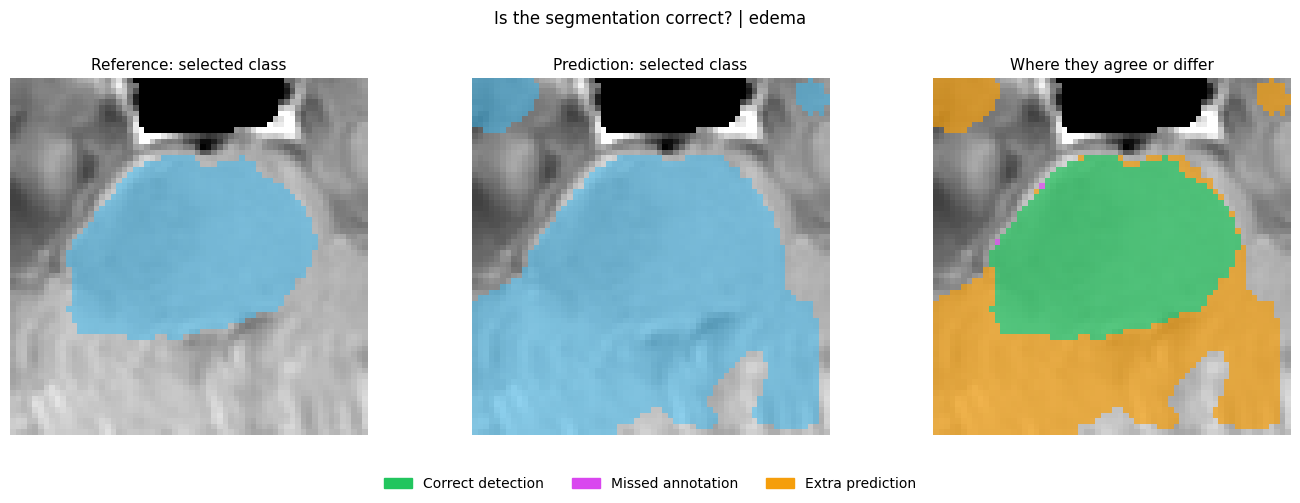

**Whole-crop measurements**

| Class | Annotated voxels | Predicted voxels | Dice |
|---|---:|---:|---:|
| background | 230,289 | 153,950 | 0.799 |
| necrotic core | 152 | 0 | 0.000 |
| edema | 29,418 | 108,194 | 0.421 |
| enhancing tumor | 2,285 | 0 | 0.000 |

For **edema**: **28,945 correct**, **473 missed**, and **79,249 extra** voxels. Precision = **0.268**; recall = **0.984**. Dice ranges from 0 (no overlap) to 1 (perfect overlap); an empty reference and prediction give n/a.

**Interpretation:** extra predicted voxels outnumber correctly detected voxels. The model overpredicts this class on this crop. A plausible XAI map would not fix this error.

In [29]:
error_labels = np.zeros(reference.shape, dtype=np.uint8)
error_labels[correct], error_labels[missed], error_labels[extra] = 1, 2, 3
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, title in zip(axes, ["Reference: selected class", "Prediction: selected class", "Where they agree or differ"]):
    mri_axis(ax, title=title)
overlay(axes[0], truth, TARGET_COLOR)
overlay(axes[1], pred, TARGET_COLOR)
errors_shown = np.ma.masked_where(view(error_labels) == 0, view(error_labels))
axes[2].imshow(errors_shown, cmap=ListedColormap(ERROR_COLORS), vmin=0, vmax=3,
               alpha=0.7, origin="lower", interpolation="nearest")
fig.legend(handles=[Patch(color=ERROR_COLORS[i], label=name) for i, name in
                    [(1, "Correct detection"), (2, "Missed annotation"), (3, "Extra prediction")]],
           loc="lower center", ncol=3, frameon=False)
fig.suptitle(f"Is the segmentation correct? | {CLASS_NAMES[TARGET_CLASS]}")
fig.tight_layout(rect=(0, 0.10, 1, 0.94))
figures["02_errors"] = fig
plt.show()

tp, fn, fp = int(correct.sum()), int(missed.sum()), int(extra.sum())
precision = tp / (tp + fp) if tp + fp else None
recall = tp / (tp + fn) if tp + fn else None
target_metrics = metrics[TARGET_CLASS]
def fmt(value):
    return "n/a" if value is None else f"{value:.3f}"
rows = "\n".join(f"| {r['name']} | {r['reference_voxels']:,} | {r['predicted_voxels']:,} | {fmt(r['dice'])} |" for r in metrics)
explain("**Whole-crop measurements**\n\n| Class | Annotated voxels | Predicted voxels | Dice |\n"
        "|---|---:|---:|---:|\n" + rows +
        f"\n\nFor **{CLASS_NAMES[TARGET_CLASS]}**: **{tp:,} correct**, **{fn:,} missed**, "
        f"and **{fp:,} extra** voxels. Precision = **{fmt(precision)}**; recall = **{fmt(recall)}**. "
        "Dice ranges from 0 (no overlap) to 1 (perfect overlap); an empty reference and prediction give n/a.")
if fp > tp:
    explain("**Interpretation:** extra predicted voxels outnumber correctly detected voxels. "
            "The model overpredicts this class on this crop. A plausible XAI map would not fix this error.")
if fn > tp:
    explain("**Interpretation:** missed annotated voxels outnumber correctly detected voxels. "
            "The model misses much of this class on this crop.")


## 5. State exactly what the explanation measures

The **region of interest (ROI)** is an output region, not a mask applied to the input. It stays fixed throughout every explanation.

- `reference`: explain the score inside the annotated target region.
- `predicted`: explain the score inside the selected-class prediction.
- `false_positive`: explain the score inside its extra predictions.
- `false_negative`: explain the score inside its missed annotations.

The score is the **mean selected-class probability in that ROI**. This is not Dice and is not the fraction of correctly segmented voxels. The input areas influencing the score may lie outside the ROI.


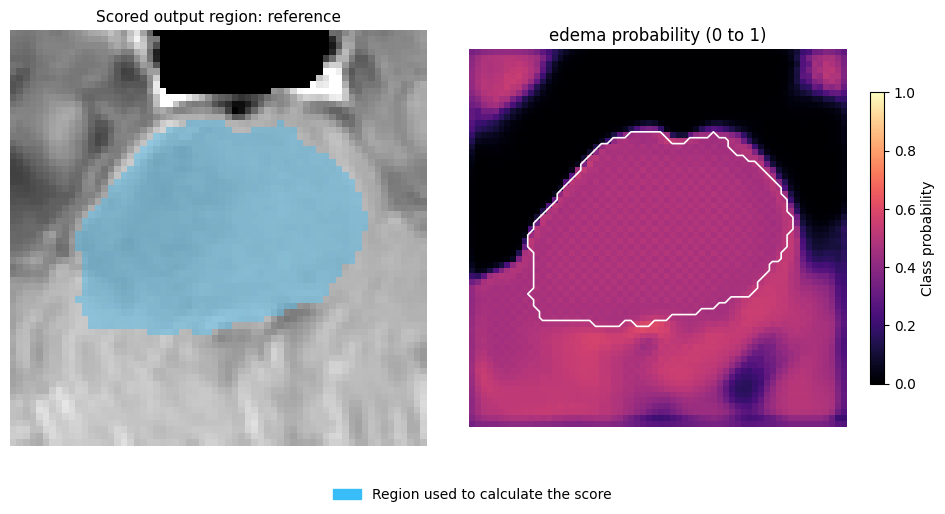

**The question:** which inputs influence the mean **edema probability** inside the **reference region**?

The original score is **47.07%**, averaged over **29,418 voxels** in the whole crop. The white outline marks this output region on the probability image. Bright pixels show a high probability, not certainty of a correct annotation.

In [30]:
roi_choices = {"reference": truth, "predicted": pred, "false_positive": extra, "false_negative": missed}
roi_array = roi_choices[ROI_MODE]
if not roi_array.any():
    raise ValueError(f"Empty {ROI_MODE} region for {CLASS_NAMES[TARGET_CLASS]}. "
                     "Choose a nonempty ROI mode, another class, or another case; no automatic substitution is made.")
roi = torch.from_numpy(roi_array.astype(np.float32)).to(DEVICE)
def target_score(output):
    return (output.softmax(dim=1)[0, TARGET_CLASS] * roi).sum() / roi.sum()
with torch.no_grad():
    original_score = float(target_score(original_logits))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
mri_axis(axes[0], title=f"Scored output region: {ROI_MODE}")
overlay(axes[0], roi_array, TARGET_COLOR, alpha=0.4)
shown = axes[1].imshow(view(probability), origin="lower", cmap="magma", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title(f"{CLASS_NAMES[TARGET_CLASS]} probability (0 to 1)")
axes[1].axis("off")
outline(axes[1], roi_array)
fig.colorbar(shown, ax=axes[1], shrink=0.7, label="Class probability")
fig.legend(handles=[Patch(color=TARGET_COLOR, label="Region used to calculate the score")],
           loc="lower center", frameon=False)
fig.tight_layout(rect=(0, 0.10, 1, 1))
figures["03_question"] = fig
plt.show()
explain(f"**The question:** which inputs influence the mean **{CLASS_NAMES[TARGET_CLASS]} probability** "
        f"inside the **{ROI_MODE.replace('_', ' ')} region**?\n\n"
        f"The original score is **{100 * original_score:.2f}%**, averaged over **{int(roi_array.sum()):,} voxels** in the whole crop. "
        "The white outline marks this output region on the probability image. Bright pixels show a high probability, not certainty of a correct annotation.")
if not roi_array[:, :, z].any():
    explain("**Slice note:** the ROI is nonempty in 3D but absent from this slice. Change the displayed slice to inspect it directly.")
del original_logits


## 6. Main XAI experiment: hide a block and measure the change

I set one **16 x 16 x 16 input block** to zero in all four modalities, run the model again, and calculate:

**change = original ROI score - score after masking**

A positive change means removing that block lowers the score. A negative change means removal raises it. I report changes in **percentage points (pp)**: 60% to 55% is a drop of 5 pp, not a relative drop of 5%.

The output ROI remains fixed. Blocks describe input interventions, not detected tumor regions. A zero block is artificial, and conclusions depend on this replacement and block size.


In [31]:
def block_slices(shape, size):
    for origin in itertools.product(*(range(0, n, size) for n in shape)):
        yield tuple(slice(s, min(s + size, n)) for s, n in zip(origin, shape))

blocks = list(block_slices(reference.shape, OCCLUSION_SIZE))
occlusion_map = np.zeros(reference.shape, dtype=np.float32)
block_drops = []
with torch.no_grad():
    for i, block in enumerate(blocks):
        modified = x.clone()
        modified[(slice(None), slice(None)) + block] = 0
        drop = original_score - float(target_score(model(modified)))
        occlusion_map[block] = drop
        block_drops.append(drop)
        if (i + 1) % 16 == 0 or i + 1 == len(blocks):
            print(f"Occlusion: {i + 1}/{len(blocks)} blocks")
assert np.isfinite(occlusion_map).all()
print("Probability-drop range:", float(occlusion_map.min()), float(occlusion_map.max()))


Occlusion: 16/64 blocks
Occlusion: 32/64 blocks
Occlusion: 48/64 blocks
Occlusion: 64/64 blocks
Probability-drop range: -0.0006847977638244629 0.09037098288536072


### A concrete before/after example

Among blocks crossing the displayed slice, I choose the one with the largest absolute score change. This is a deliberately selected example, not a typical or unbiased block. The yellow rectangle shows the input block; the white contour shows the separate output ROI whose score is measured.


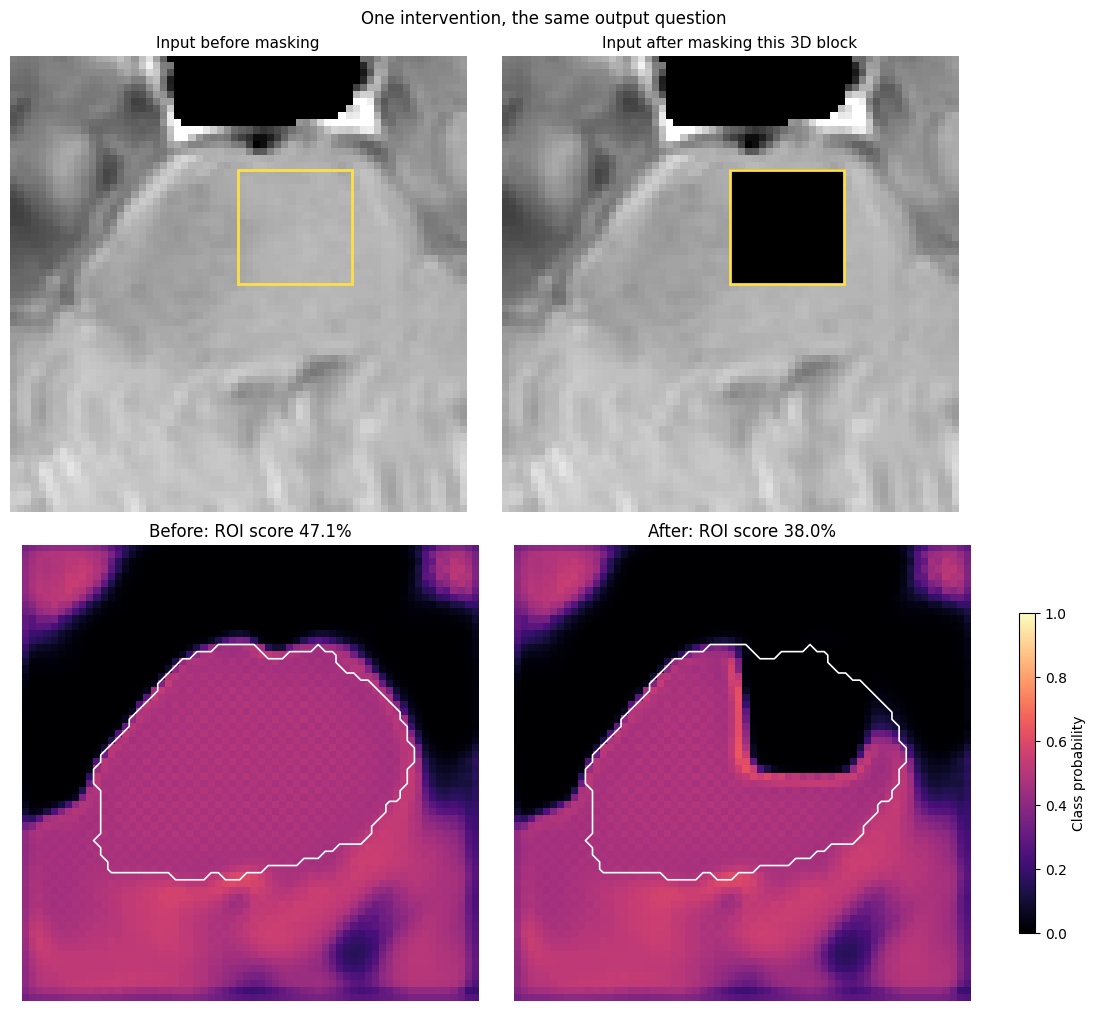

**Read this example:** masking this block **lowered** the score from **47.07%** to **38.04%**, a change of **9.04 percentage points**. The score averages the entire 3D ROI, while these images show one slice. This tells us how the network reacts to that intervention; it does not prove that the block is tumor or that the prediction is correct.

In [32]:
visible_blocks = [i for i, b in enumerate(blocks) if b[2].start <= z < b[2].stop]
example_index = max(visible_blocks, key=lambda i: abs(block_drops[i]))
example_block = blocks[example_index]
modified = x.clone()
modified[(slice(None), slice(None)) + example_block] = 0
with torch.no_grad():
    modified_probability = model(modified).softmax(dim=1)[0, TARGET_CLASS].cpu().numpy()
masked_score = float(modified_probability[roi_array].mean())
masked_mri = background.copy()
masked_mri[example_block] = 0
fig, axes = plt.subplots(2, 2, figsize=(11, 10), layout="constrained")
mri_axis(axes[0, 0], title="Input before masking")
mri_axis(axes[0, 1], array=masked_mri, title="Input after masking this 3D block")
for ax in axes[0]:
    b = example_block
    ax.add_patch(Rectangle((b[0].start - 0.5, b[1].start - 0.5),
                          b[0].stop - b[0].start, b[1].stop - b[1].start,
                          fill=False, edgecolor="#fde047", linewidth=2))
for ax, array, title in [(axes[1, 0], probability, f"Before: ROI score {original_score:.1%}"),
                          (axes[1, 1], modified_probability, f"After: ROI score {masked_score:.1%}")]:
    shown = ax.imshow(view(array), cmap="magma", vmin=0, vmax=1, origin="lower", interpolation="nearest")
    outline(ax, roi_array)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(shown, ax=list(axes[1]), shrink=0.7, label="Class probability")
fig.suptitle("One intervention, the same output question")
figures["04_masking_example"] = fig
plt.show()
example_drop_pp = 100 * (original_score - masked_score)
direction = "lowered" if example_drop_pp >= 0 else "raised"
explain(f"**Read this example:** masking this block **{direction}** the score from **{original_score:.2%}** "
        f"to **{masked_score:.2%}**, a change of **{abs(example_drop_pp):.2f} percentage points**. "
        "The score averages the entire 3D ROI, while these images show one slice. "
        "This tells us how the network reacts to that intervention; it does not prove that the block is tumor or that the prediction is correct.")
assert abs((original_score - masked_score) - block_drops[example_index]) < 1e-5
del modified


### Summarize all masked blocks on this slice

**Red:** masking lowers the score. **Blue:** masking raises the score. **Near white:** little change. The square pattern is expected: one value is assigned to each 3D block, without smoothing.

The map is translucent over the MRI, and the white outline still marks the output ROI. All displayed values are raw score changes in percentage points. A small change is not stretched to look like a large probability.


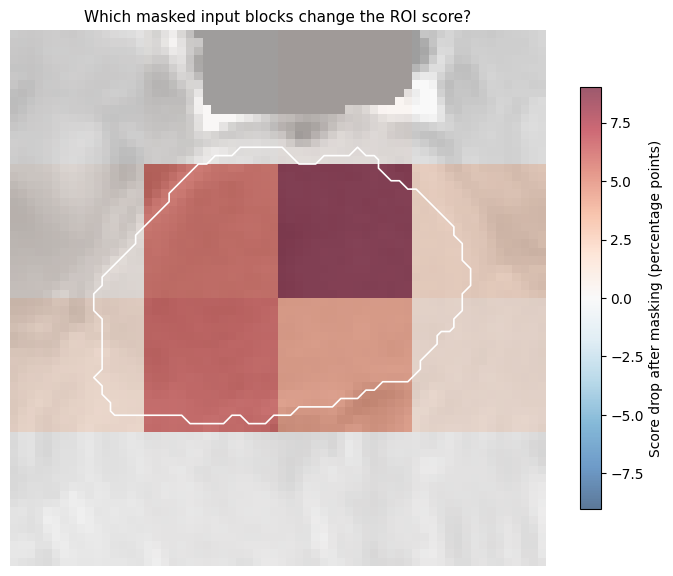

**Across all 64 blocks in the 3D crop:** the score change ranges from **-0.07 to +9.04 pp**. Read location and sign together: a red block supports the original score under this removal experiment. Its position need not coincide with the annotated region.

In [33]:
occlusion_pp = 100 * occlusion_map
limit_pp = max(float(np.max(np.abs(occlusion_pp))), 1e-6)
fig, ax = plt.subplots(figsize=(7, 6))
mri_axis(ax, title="Which masked input blocks change the ROI score?")
shown = ax.imshow(view(occlusion_pp), origin="lower", cmap="RdBu_r", vmin=-limit_pp, vmax=limit_pp,
                  alpha=0.65, interpolation="nearest")
outline(ax, roi_array)
fig.colorbar(shown, ax=ax, shrink=0.75, label="Score drop after masking (percentage points)")
fig.tight_layout()
figures["05_occlusion"] = fig
plt.show()
block_values = 100 * np.asarray(block_drops)
explain(f"**Across all {len(blocks)} blocks in the 3D crop:** the score change ranges from "
        f"**{block_values.min():+.2f} to {block_values.max():+.2f} pp**. "
        "Read location and sign together: a red block supports the original score under this removal experiment. "
        "Its position need not coincide with the annotated region.")


## 7. Which MRI modality changes this score most when removed?

This is a different intervention: I replace a **whole channel** with zeros. The chart shows the remaining score, alongside the original score. A larger difference means a larger effect for this particular patient, ROI, and replacement.

The four input images share a grayscale range of 0 to 1 here because preprocessing normalized them. Their brightness is not an attribution. Removing a complete sequence can create unrealistic inputs, and interactions mean these effects are not independent contributions.


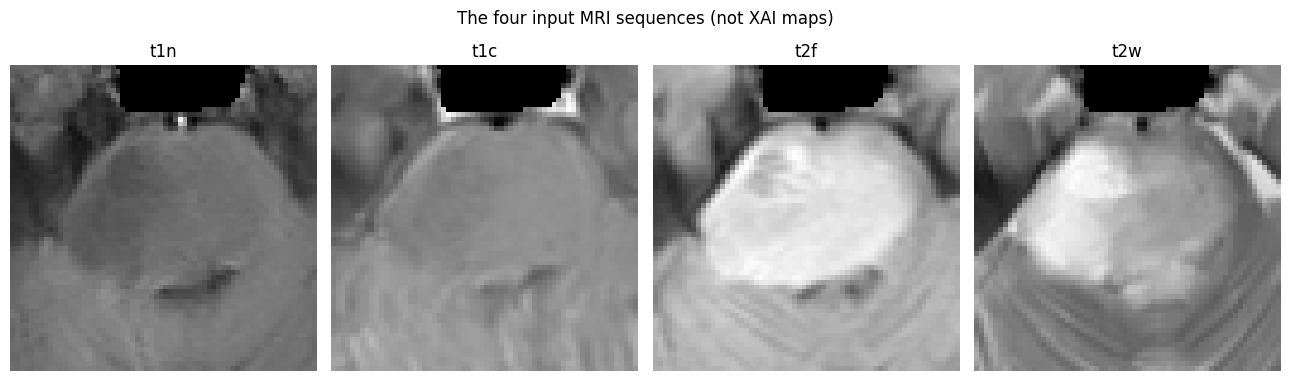

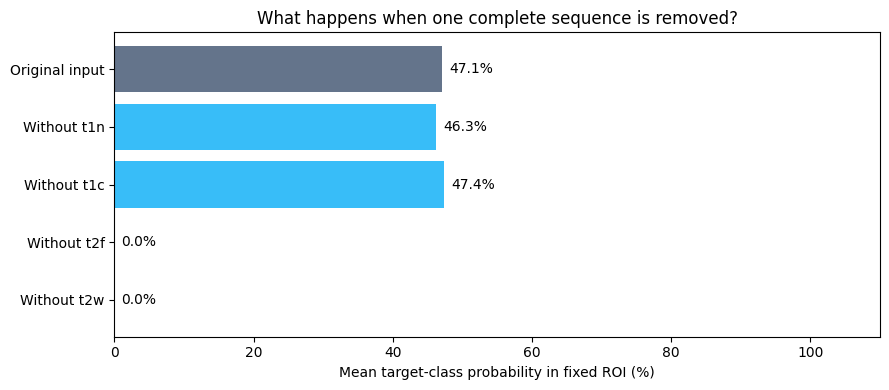

| Removed sequence | Score after removal | Original minus new score |
|---|---:|---:|
| t1n | 46.28% | +0.80 pp |
| t1c | 47.39% | -0.31 pp |
| t2f | 0.00% | +47.07 pp |
| t2w | 0.00% | +47.07 pp |

**Read this chart:** removing **t2f** has the largest absolute effect (**+47.07 pp** signed drop). This is dependence under an artificial intervention, not proof that this modality is always the most useful.

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for c, ax in enumerate(axes):
    ax.imshow(view(image_crop[..., c]), cmap="gray", vmin=0, vmax=1, origin="lower", interpolation="nearest")
    ax.set_title(MODALITIES[c])
    ax.axis("off")
fig.suptitle("The four input MRI sequences (not XAI maps)")
fig.tight_layout()
figures["06_modalities"] = fig
plt.show()
ablation = []
with torch.no_grad():
    for c, name in enumerate(MODALITIES):
        modified = x.clone()
        modified[:, c] = 0
        ablated_score = float(target_score(model(modified)))
        ablation.append({"modality": name, "score": ablated_score,
                         "probability_drop": original_score - ablated_score})
fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(5)
values = [100 * original_score] + [100 * r["score"] for r in ablation]
ax.barh(positions, values, color=["#64748b"] + ["#38bdf8"] * 4)
ax.set_yticks(positions, ["Original input"] + [f"Without {r['modality']}" for r in ablation])
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("Mean target-class probability in fixed ROI (%)")
ax.set_title("What happens when one complete sequence is removed?")
for i, value in enumerate(values):
    ax.text(value + 1, i, f"{value:.1f}%", va="center")
fig.tight_layout()
figures["07_ablation"] = fig
plt.show()
rows = "\n".join(f"| {r['modality']} | {100*r['score']:.2f}% | {100*r['probability_drop']:+.2f} pp |" for r in ablation)
explain("| Removed sequence | Score after removal | Original minus new score |\n|---|---:|---:|\n" + rows)
strongest = max(ablation, key=lambda r: abs(r['probability_drop']))
explain(f"**Read this chart:** removing **{strongest['modality']}** has the largest absolute effect "
        f"(**{100*strongest['probability_drop']:+.2f} pp** signed drop). "
        "This is dependence under an artificial intervention, not proof that this modality is always the most useful.")


## 8. Write a cautious conclusion from this run

This summary is generated from the current arrays, rather than copied from a previous run. It separates segmentation quality from explanation behavior.


In [35]:
missed_classes = [r["name"] for r in metrics[1:] if r["reference_voxels"] > 0 and r["predicted_voxels"] == 0]
summary_text = (
    f"**Patient:** `{image_path.name}`; **class:** {CLASS_NAMES[TARGET_CLASS]}; **ROI:** {ROI_MODE.replace('_', ' ')}.\n\n"
    f"- **Segmentation:** crop Dice is {fmt(target_metrics['dice'])}; {fp:,} extra and {fn:,} missed target-class voxels.\n"
    f"- **Question explained:** mean class probability in the fixed ROI, originally {original_score:.2%}.\n"
    f"- **One block example:** masking changes it from {original_score:.2%} to {masked_score:.2%}.\n"
    f"- **Modality intervention:** removing {strongest['modality']} produces the largest absolute score change.\n"
)
if missed_classes:
    summary_text += f"- **Fully missed annotated classes in this crop:** {', '.join(missed_classes)}.\n"
summary_text += ("\n**What I can conclude:** I measured this checkpoint's response to specified input changes. "
                 "**What remains unproven:** accuracy on other patients, clinical usefulness, and whether the maps isolate biological causes. "
                 "An attractive map does not repair a segmentation error.")
explain(summary_text)


**Patient:** `image_11.npy`; **class:** edema; **ROI:** reference.

- **Segmentation:** crop Dice is 0.421; 79,249 extra and 473 missed target-class voxels.
- **Question explained:** mean class probability in the fixed ROI, originally 47.07%.
- **One block example:** masking changes it from 47.07% to 38.04%.
- **Modality intervention:** removing t2f produces the largest absolute score change.
- **Fully missed annotated classes in this crop:** necrotic core, enhancing tumor.

**What I can conclude:** I measured this checkpoint's response to specified input changes. **What remains unproven:** accuracy on other patients, clinical usefulness, and whether the maps isolate biological causes. An attractive map does not repair a segmentation error.

## 9.  gradient sensitivity

The main interpretation above is complete without this section. Set `RUN_GRADIENT_APPENDIX = False` to skip it.

**Gradient x input** combines local gradients with input intensity. **SmoothGrad** averages signed input gradients over noisy inputs; Gaussian noise is not clipped. Neither map is a probability image or a tumor mask.

The first comparison uses absolute magnitude summed over channels: brighter means greater local sensitivity, not more tumor. Each method has its own explicitly labeled scale, capped at its 99th percentile for visibility. Signed, per-modality maps follow for detailed inspection. Raw values remain available in the export.


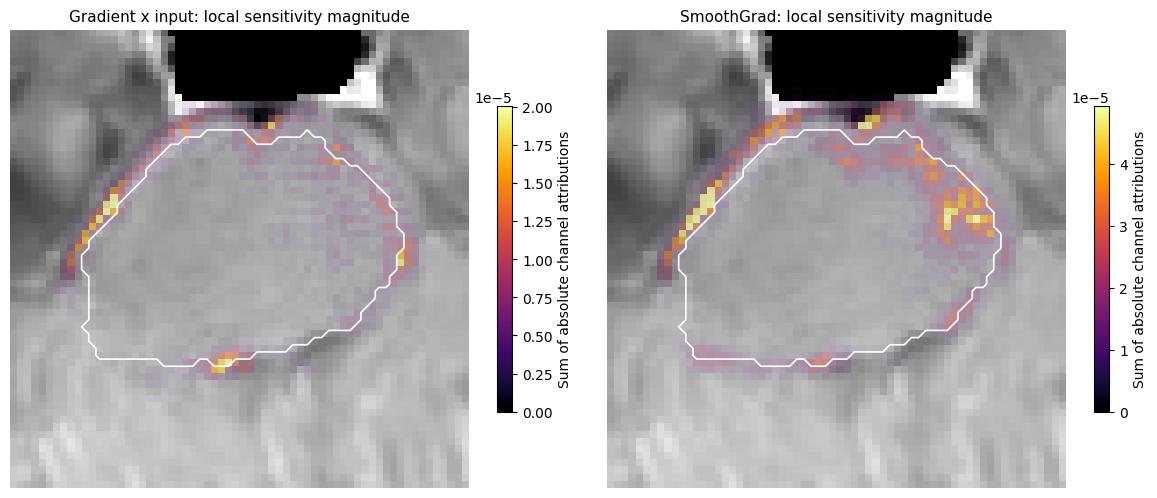

**Reading these images:** the white outline is the output ROI; bright areas are input sensitivity. The two color scales differ and cannot be compared by brightness. SmoothGrad split-half cosine similarity is **0.919**. This measures agreement between two noise subsets, not correctness of the segmentation.

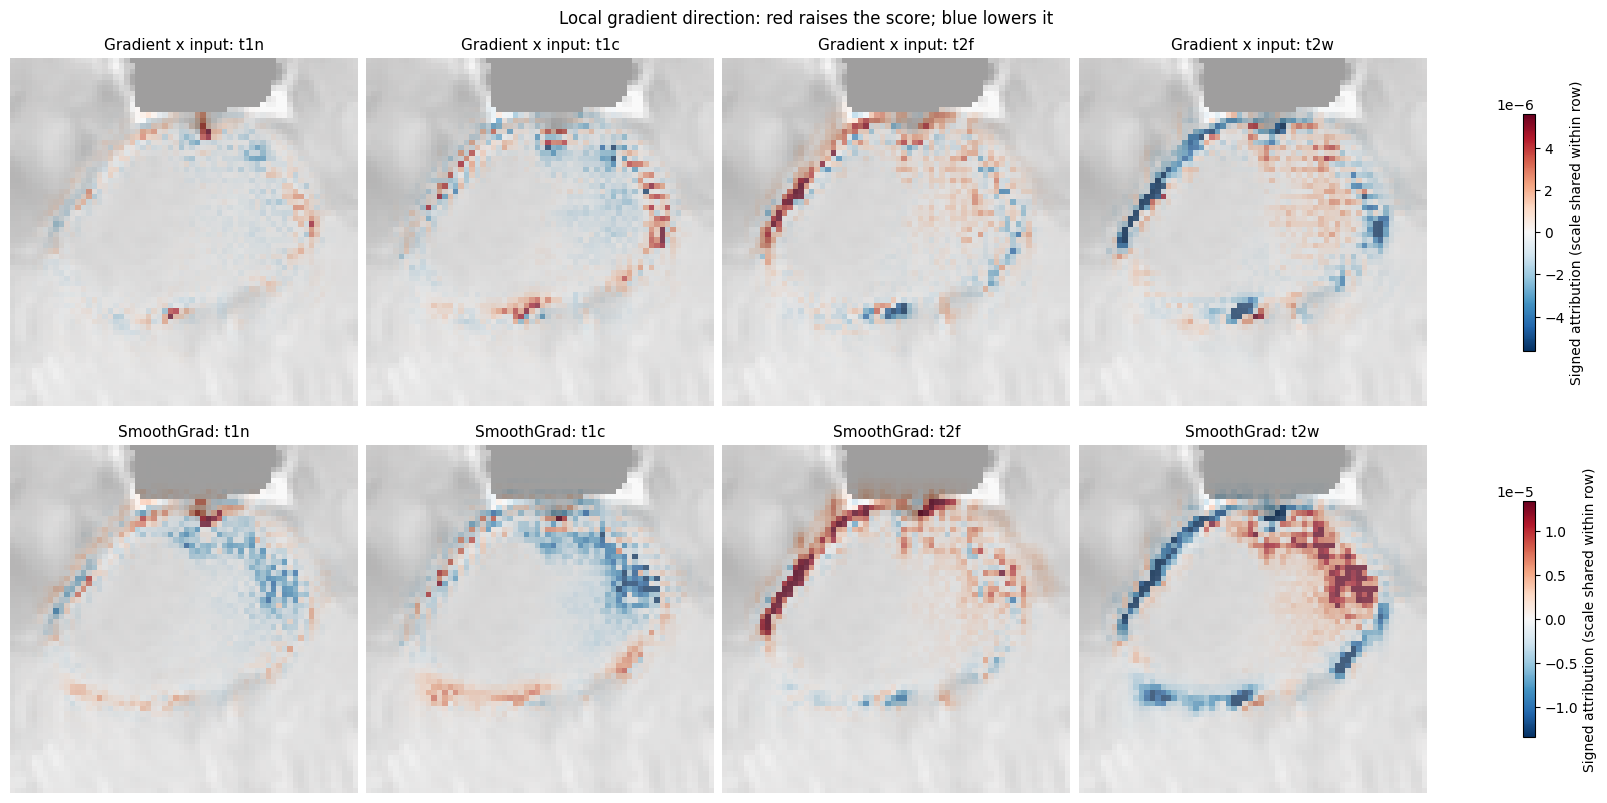

In [36]:
def input_gradient(inputs):
    with torch.enable_grad():
        sample = inputs.detach().clone().requires_grad_(True)
        output = model(sample)
        gradient = torch.autograd.grad(target_score(output), sample)[0]
    return gradient.detach()

def smooth_grad(inputs, samples, noise_std):
    generator = torch.Generator(device=inputs.device).manual_seed(SEED)
    first, second = torch.zeros_like(inputs), torch.zeros_like(inputs)
    half = samples // 2
    for i in range(samples):
        noise = torch.randn(inputs.shape, device=inputs.device, dtype=inputs.dtype, generator=generator) * noise_std
        gradient = input_gradient(inputs + noise)
        if i < half:
            first += gradient
        else:
            second += gradient
    a, b = first / half, second / (samples - half)
    norm = a.norm() * b.norm()
    similarity = float((a * b).sum() / norm) if norm.item() > 0 else None
    return (first + second) / samples, similarity

gradient_x_input = smooth_map = None
smooth_similarity = None
if RUN_GRADIENT_APPENDIX:
    gradient = input_gradient(x)
    gradient_x_input = (gradient * x).cpu().numpy()[0]
    smoothed, smooth_similarity = smooth_grad(x, SMOOTH_SAMPLES, NOISE_STD)
    smooth_map = smoothed.cpu().numpy()[0]
    for name, array in [("Gradient x input", gradient_x_input), ("SmoothGrad", smooth_map)]:
        assert np.isfinite(array).all()
        if not np.any(array):
            warnings.warn(f"{name} is zero; a blank map is not evidence of no biological relevance.")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, name, array in [(axes[0], "Gradient x input", gradient_x_input),
                             (axes[1], "SmoothGrad", smooth_map)]:
        magnitude = np.abs(array).sum(axis=0)
        scale = max(float(np.percentile(magnitude, 99)), 1e-12)
        mri_axis(ax, title=f"{name}: local sensitivity magnitude")
        heat = view(magnitude)
        alpha = 0.75 * np.clip(heat / scale, 0, 1)
        shown = ax.imshow(heat, cmap="inferno", vmin=0, vmax=scale, alpha=alpha,
                          origin="lower", interpolation="nearest")
        outline(ax, roi_array)
        # An opaque colorbar avoids confusing transparency with numerical scale.
        bar = plt.cm.ScalarMappable(norm=shown.norm, cmap=shown.cmap)
        fig.colorbar(bar, ax=ax, shrink=0.65, label="Sum of absolute channel attributions")
    fig.tight_layout()
    figures["08_gradient_sensitivity"] = fig
    plt.show()
    similarity_text = "undefined (zero gradient norm)" if smooth_similarity is None else f"{smooth_similarity:.3f}"
    explain("**Reading these images:** the white outline is the output ROI; bright areas are input sensitivity. "
            "The two color scales differ and cannot be compared by brightness. "
            f"SmoothGrad split-half cosine similarity is **{similarity_text}**. "
            "This measures agreement between two noise subsets, not correctness of the segmentation.")
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
    for row, (name, array) in enumerate([("Gradient x input", gradient_x_input), ("SmoothGrad", smooth_map)]):
        limit = max(float(np.percentile(np.abs(array), 99)), 1e-12)
        for c, ax in enumerate(axes[row]):
            mri_axis(ax, title=f"{name}: {MODALITIES[c]}")
            shown = ax.imshow(view(array[c]), cmap="RdBu_r", vmin=-limit, vmax=limit,
                              alpha=0.65, origin="lower", interpolation="nearest")
        fig.colorbar(plt.cm.ScalarMappable(norm=shown.norm, cmap=shown.cmap),
                     ax=list(axes[row]), shrink=0.65, label="Signed attribution (scale shared within row)")
    fig.suptitle("Local gradient direction: red raises the score; blue lowers it")
    figures["09_signed_gradients"] = fig
    plt.show()
    del gradient, smoothed
else:
    explain("Gradient appendix skipped. The occlusion and modality results above are sufficient for the main walkthrough.")


## 10. Save the figures and the interpretation

The export includes labeled figures, raw maps, class errors, crop coordinates, settings, and the generated conclusion. These arrays are in preprocessed coordinates; they are not scanner-space NIfTI volumes. The training notebooks and model checkpoint are unchanged.


In [37]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
run_name = f"{image_path.stem}_class{TARGET_CLASS}_{ROI_MODE}_crop{CROP_SIZE}"
arrays = dict(occlusion=occlusion_map, prediction=prediction, reference=reference,
              roi=roi_array, crop_start=start, image=image_crop, class_probability=probability,
              errors=error_labels)
if RUN_GRADIENT_APPENDIX:
    arrays.update(gradient_x_input=gradient_x_input, smoothgrad=smooth_map)
np.savez_compressed(OUTPUT_DIR / f"{run_name}_maps.npz", **arrays)
summary = {
    "version": 3, "case": image_path.name, "checkpoint": str(CHECKPOINT.resolve()),
    "target_class": TARGET_CLASS, "class_name": CLASS_NAMES[TARGET_CLASS],
    "roi_mode": ROI_MODE, "roi_voxels": int(roi_array.sum()),
    "crop_selection": selection, "crop_start": start.tolist(), "crop_size": CROP_SIZE,
    "local_slice": z, "score": "mean class probability in fixed ROI", "original_score": original_score,
    "class_metrics": metrics, "selected_class_precision": precision, "selected_class_recall": recall,
    "error_labels": {"0": "outside selected-class errors/detections", "1": "correct", "2": "missed", "3": "extra"},
    "example_block": [[b.start, b.stop] for b in example_block], "example_score_after": masked_score,
    "occlusion_size": OCCLUSION_SIZE, "occlusion_replacement": 0, "occlusion_channels": "all four jointly",
    "modality_ablation": ablation, "gradient_appendix": RUN_GRADIENT_APPENDIX,
    "smooth_samples": SMOOTH_SAMPLES, "noise_std": NOISE_STD, "noise_clipped": False,
    "smooth_split_half_cosine": smooth_similarity, "seed": SEED,
    "torch_version": torch.__version__, "numpy_version": np.__version__,
}
(OUTPUT_DIR / f"{run_name}_summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
(OUTPUT_DIR / f"{run_name}_interpretation.md").write_text(summary_text + "\n", encoding="utf-8")
for name, figure in figures.items():
    figure.savefig(OUTPUT_DIR / f"{run_name}_{name}.png", dpi=130, bbox_inches="tight")
print("Saved", len(figures), "figures, raw maps, settings, and interpretation to:", OUTPUT_DIR.resolve())


Saved 9 figures, raw maps, settings, and interpretation to: C:\Users\Mahugnon\Documents\Medical Imaging\Segmentation with 3 U-Net\lightweight-brats-tutorial-main\notebooks\xai_results_guided


## Try one change at a time

Start by reading the reference/prediction/error figure without XAI. Then explain a nonempty `false_positive` or `false_negative` ROI and compare it with the reference-region question. Try class 3 in reference mode to study a missed tumor class.

Only after that, reduce `OCCLUSION_SIZE` to 8 for finer blocks (many more forward passes), or try another patient. Changing the crop or class may change the displayed slice; keep track of this before comparing figures. These are single-case analyses, not a validation study.
